<a href="https://colab.research.google.com/github/bondiolandia/TP_Laboratorio_de_M-todos_Cuantitativos_2026/blob/main/notebook_evolucion_del_anime.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Holas Chicas!!
Para commitear un cambio, una vez que escriben el codigo, van a Archivo > Guardar. Una vez guardado van Archivo > Guardar una copia en Github; agregan un comentario que describa los cambios que estan pusheando y le dan OK.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib as mp
import seaborn as sb
import numpy as np

#**¿Qué factores influyen en que un anime sea más popular que otro?**

Aunque en su país de origen, la palabra anime se refiere a todo tipo de animacion de todo el mundo, fuera de este, el término "anime", es un término con el que se identifica a la animacion de procedencia japonesa.

Este genero de animacion tiene una considerable cantidad de fans no solo en su país de origen, sino en todas partes del mundo, prueba de esto es que el mercado mundial de anime alcanzó un valor de 46.540 millones de dólares en 2026 y se espera que incremente a 96.970 millones de dólares en 2034.

Por lo que, no solo como fanes, sino como clientas activas del anime, queremos ver la popularidad de los animes de forma mas analítica.

Myanimelist: La mayor base de datos y red social de anime, la cual contiene miles de fichas oficiales de animes que cualquiera puede ver, permitiendole a sus usuarios calificarlos a su antojo.

Dicho esto, desde el punto de vista de que los animes mas aclamados por los espectadores fueron uno de los principales aspectos que hicieron este incremento tan exponencial de la visualizacion de anime, hemos encontrado un Dataset publico en kaggle, que extrajo desde Myanimelist informacion de mas de 30.000 animes y sus calificaciones, de modo que, nos encargaremos de analizarlo para hallar cuales son los factores que influyeron en las mejores calificaciones.


Hacemos una primera exploración de los datos que tenemos.

In [ ]:
# Importamos la libreria de Kaggle y el data set con el que vamos a trabajar
import kagglehub as kg
from kagglehub import KaggleDatasetAdapter

camino = "anime-dataset-2026.csv"
Datos = kg.dataset_load(KaggleDatasetAdapter.PANDAS,"darkbarrierhub/anime-dataset-2026",camino)

# Seleccionamos una porcion de los datos para explorar
muestra = pd.concat([Datos.head(),Datos.tail()])
display(muestra)

# Describimos la estructura de la tabla: dimensiones, columnas, tipos de dato (.dtypes).
filas, columnas = Datos.shape

print(f"El DF orginal tiene {filas} y {columnas} columnas\n")
Datos.info()



Using Colab cache for faster access to the 'anime-dataset-2026' dataset.


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.24,"Action, Drama, Mystery, Supernatural, Detective","Though hidden away from the general public, Wi...",TV,26,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min. per ep.,PG-13 - Teens 13 or older,3558,2003,720,46691,132072,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.97,"Action, Adventure, Fantasy, Shounen",It is the dark century and the people are suff...,TV,52,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min. per ep.,PG - Children,5016,6031,18,6983,16793,https://cdn.myanimelist.net/images/anime/7/215...
30758,65097,AIYOU,AIYOU,AIYOU,UNKNOWN,Music,Music video for the song AIYOU by Eve. The son...,Music,1,"Oct 2, 2026",...,UNKNOWN,Original,2 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1900/...
30759,65098,22 Durnham Dew,UNKNOWN,22 Durnham Dew,UNKNOWN,"Slice of Life, Music",Music video for the song 22 Durnham Dew by Ben...,Music,1,"Jul 28, 2026",...,UNKNOWN,Original,1 min.,G - All Ages,UNKNOWN,30608,0,UNKNOWN,16,https://cdn.myanimelist.net/images/anime/1045/...
30760,65099,"Ghost (Music, 2026)",UNKNOWN,GHOST,UNKNOWN,"Sci-Fi, Music, Racing","Music video for the song Ghost by lIlBOI, BIG ...",Music,1,"Oct 2, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,UNKNOWN,30605,0,UNKNOWN,21,https://cdn.myanimelist.net/images/anime/1833/...
30761,65100,Angels on the Dancefloor,UNKNOWN,Angels On The Dancefloor,UNKNOWN,"Music, Video Game",Music video for the song Angels On The Dancefl...,Music,1,"May 29, 2026",...,Mimoid,Original,4 min.,PG-13 - Teens 13 or older,UNKNOWN,30607,0,UNKNOWN,18,https://cdn.myanimelist.net/images/anime/1845/...
30762,65101,Goemul,Monster,괴물,UNKNOWN,Music,Music video for the song Goemul by WE GO-6.,Music,1,"Sep 22, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1239/...


El DF orginal tiene 30763 y 24 columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30763 entries, 0 to 30762
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   anime_id      30763 non-null  int64 
 1   Name          30763 non-null  object
 2   English name  30763 non-null  object
 3   Other name    30763 non-null  object
 4   Score         30763 non-null  object
 5   Genres        30763 non-null  object
 6   Synopsis      30763 non-null  object
 7   Type          30763 non-null  object
 8   Episodes      30763 non-null  object
 9   Aired         30763 non-null  object
 10  Premiered     30763 non-null  object
 11  Status        30763 non-null  object
 12  Producers     30763 non-null  object
 13  Licensors     30763 non-null  object
 14  Studios       30763 non-null  object
 15  Source        30763 non-null  object
 16  Duration      30763 non-null  object
 17  Rating        30182 non-null  object
 18  Rank 

Para analizar de forma rapida la cobertura temporal usamos el siguiente prompt:


```
# La columna de "airing" me serviria para saber que cobertura temporal tiene la tabla. Escribi unas lineas de codigo (py) para normalizarla de forma sencilla usando esta logica: extrae todas las fechas numericas (solo YYYY) que figuran en la columna airing, arma un array con ellas y busca min y max. El objetivo es poder normalizar el formato de fecha para extraer cual es la fecha mas antigua y cual la mas reciente, para inferir la cobertura temporal de los datos
```



In [ ]:

## Extraer todos los años (4 dígitos) de cada fila de "Aired"
anios_por_fila = Datos["Aired"].astype(str).str.findall(r"\b(\d{4})\b")

## Aplanar en un único array de enteros
anios = pd.Series([int(a) for lista in anios_por_fila for a in lista])

## Finalmente vemos la cobertura
print("Años extraídos:", len(anios))
print("Año más antiguo:", anios.min())
print("Año más reciente:", anios.max(), "(Puede contener futuros estrenos)")
print(f"Filas sin ningún año: {(anios_por_fila.str.len() == 0).sum()} de {len(Datos)}")

Años extraídos: 41752
Año más antiguo: 1917
Año más reciente: 2028 (Puede contener futuros estrenos)
Filas sin ningún año: 887 de 30763


Miramos ahora la calidad de los datos y algunas medidas descriptivas

In [ ]:
# Analizamos la calidad: valores nulos, duplicados y estadísticas descriptivas
filas = []

for col in Datos.columns:
    n_nulos = Datos[col].isnull().sum()
    if n_nulos > 0:  # solo columnas con nulos
        filas.append({
            "columna": col,
            "filas_nulas": n_nulos
        })

resumen_nulos = pd.DataFrame(filas).sort_values("filas_nulas", ascending=False).reset_index(drop=True)
display (resumen_nulos)
print (f"Cantidad de filas duplicadas: {Datos.duplicated().sum()}")

Datos.describe().T

,columna,filas_nulas
0,Rating,581


Cantidad de filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
anime_id,30763.0,35685.588597,20237.227396,1.0,17684.0,39329.0,53047.5,65101.0
Popularity,30763.0,15227.872867,8880.868068,0.0,7535.5,15227.0,22918.0,30608.0
Favorites,30763.0,429.174528,4582.160441,0.0,0.0,1.0,17.0,256516.0
Members,30763.0,39192.862465,170966.328008,0.0,241.0,1051.0,9162.0,4434071.0


# **Conclusiones**
* La lectura del .info() nos dice dos cosas importantes: una porque es mentira y otra porque afecta todo el trabajo. La mentira: No existen columnas sin datos (no existen columnas con null). La anticipatoria: Columnas que podrian ser numericas son de tipo string.
* El Sondeo de cobertura temporal que hicimos es util pero preliminar: Es posible que el año mas reciente sea una fecha futura, pues el anime tiene una fecha posible de estreno. Por otro lado, nos dice "En que franja temporal se empezaron a emitir los animes que se incluye en la base", no cual es el momento en el que se hizo el relevamiento.
* Si nos dejasemos llevar solo por el isnull(), pensariamos que solo faltan datos en la columna Rating. Pero viendo la muestra vemos que hay celdas con valores como `"UNKNOWN", "Unknown", "Not available", "N/A"` y `"?"`. Vamos a tener que tener cuidado con estos: convertirlos a NaN o borrarlos segun lo que querramos mirar.
* No vemos filas duplicadas en su totalidad, pero si tenemos que saber que a veces se registra una serie en mas de una fila porque tiene peliculas, varias temporadas, remakes, etc.
*   Las estadisticas descriptivas de Pandas no nos sirven por el tipo de datos que tiene la base: Muchos que son conceptualmente numericos y podriamos evaluar su promedio (Numero de episodios, miembros de la pagina que lo agregaron a sus listas, ranking) no tienen un formato numerico si no que son del tipo Object. A estos tendremos que transformarlos para poder trabajarlos


**En resumen, tendremos que pensar alguna forma de sanear ciertas columnas para que nos sirvan (ej. fechas) y desechar algunas que no hacen a nuestra dimension de analisis (rating).**

In [ ]:
import kagglehub as kg #Importamos la libreria kagglehub, que es el formato en el que estan los datos.
from kagglehub import KaggleDatasetAdapter #Importamos un adaptador de kaggle que permite convertir el conjunto de datos a un formato en especifico.
import pandas as pd #Importamos pandas, para trabajar con Dataframe.

camino = "anime-dataset-2026.csv" #El camino para llegar al archivo.
Datos = kg.dataset_load(KaggleDatasetAdapter.PANDAS,"darkbarrierhub/anime-dataset-2026",camino) #El codigo encuentra el archivo con los datos siguiendo el camino y lo convierte en un formato Dataframe de pandas.

Datos.head()

Using Colab cache for faster access to the 'anime-dataset-2026' dataset.


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.24,"Action, Drama, Mystery, Supernatural, Detective","Though hidden away from the general public, Wi...",TV,26,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min. per ep.,PG-13 - Teens 13 or older,3558,2003,720,46691,132072,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.97,"Action, Adventure, Fantasy, Shounen",It is the dark century and the people are suff...,TV,52,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min. per ep.,PG - Children,5016,6031,18,6983,16793,https://cdn.myanimelist.net/images/anime/7/215...


# ¿Por qué vale la pena responder la pregunta?  
En los últimos años se ha hecho notar como el consumo de películas y series de animación japonesa se ha vuelto cada vez más masivo. De la mano de títulos taquilleros como Naruto, One Piece o Kimetsu no Yaiba, el mercado del anime, si bien es aún menor que el de la producción audiovisual tradicional, pasó de ser un nicho cultural, a masificarse con notoriedad por fuera de Japón, su país de origen. Es significativo también que artistas conocidos a nivel mundial como Bad Bunny incluyan referencias a este tipo de consumos culturales. Para considerar algunos números, (agregar notas periodísticas).

Si por sí solo el peso económico de este crecimiento acelerado no fuese suficiente, el aumento del interés en una producción asiática se enmarca también en la transformación de las relaciones de fuerzas políticas a nivel global, donde las potencias occidentales del hemisferio norte están viéndose enfrentadas al enorme crecimiento de China, y donde países cómo este, Korea, India y Japón aumentan su influencia cultural en todo el planeta. De la pandemia en adelante, el fenómeno TikTok ha jugado un rol importante como plataforma de difusión de contenido vinculado a oriente, acercandolo a un público nuevo y en un formato de fácil difusión (agregar un paper).


# **PARTE 3.3** - Transformaciones y resumen estadistico

**Transformación 1 – Limpieza de datos y conversión de tipos.**

Al revisar la información del dataset con `.info()`, observamos que las columnas *Score*, *Episodes* y *Scored By* tenían el tipo de dato `object`, ya que los valores faltantes estaban representados como `"UNKNOWN"` en lugar de `NaN`. Por este motivo, `isnull()` no identificaba estos valores como nulos y solo detectaba los faltantes de la columna *Rating*. Para solucionarlo, reemplazamos `"UNKNOWN"` por `NaN` y convertimos las columnas correspondientes a tipos numéricos. De esta manera, podemos trabajar con los datos y calcular medidas estadísticas, como el promedio y la mediana.

Asistencia de IA para el código: *"Tengo columnas numéricas que vienen como string con el valor ‘UNKNOWN’, ‘N/A’, y otros datos que no son relevantes para el análisis . Escribí código en pandas para convertirlas a NaN y pasarlas a numérico. Sin modificar el dataset original"*

In [ ]:
anime = Datos.copy()   # trabajamos sobre una copia, el original queda intacto

# 1) Placeholders -> NaN
anime = anime.replace(["UNKNOWN", "Unknown", "N/A", "Not available", "?"], np.nan)

# 2) Columnas numéricas que venían como texto
for col in ["Score", "Episodes", "Scored By"]:
    anime[col] = pd.to_numeric(anime[col], errors="coerce")

print(anime[["Score", "Episodes", "Scored By"]].dtypes)
print("\nNulos reales después de la limpieza:")
print(anime[["Score", "Episodes", "Scored By", "Genres", "Studios", "Source", "Aired"]].isnull().sum())

Score        float64
Episodes     float64
Scored By    float64
dtype: object

Nulos reales después de la limpieza:
Score        10405
Episodes       756
Scored By    10405
Genres         120
Studios      12150
Source        2694
Aired          887
dtype: int64


**Transformación 2 – Creación de las columnas Año y Década.**

La columna `Aired` contiene fechas con distintos formatos. Para poder analizar si la antigüedad de un anime se relaciona con su popularidad, extraemos el primer año de estreno y lo guardamos en una nueva columna llamada `Año`. Luego, creamos `Década` para agrupar los animes por períodos y facilitar las comparaciones.

Asistencia de IA para el código: *“¿Cómo puedo extraer el primer año de una columna con fechas en distintos formatos y crear otra columna que indique la década?”*

In [ ]:

# Transformación 2: Crear Año y Década

# Extraemos el primer año de estreno de cada anime
anime["Año"] = pd.to_numeric(
    anime["Aired"].astype("string").str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Agrupamos los años por década
anime["Década"] = (anime["Año"] // 10 * 10).astype("Int64")

# Comprobamos los resultados
print("Animes sin año identificable:", anime["Año"].isnull().sum())
print(anime[["Name", "Aired", "Año", "Década"]].head())


Animes sin año identificable: 887
                              Name                         Aired   Año  Década
0                     Cowboy Bebop   Apr 3, 1998 to Apr 24, 1999  1998    1990
1  Cowboy Bebop: Tengoku no Tobira                   Sep 1, 2001  2001    2000
2                           Trigun   Apr 1, 1998 to Sep 30, 1998  1998    1990
3               Witch Hunter Robin   Jul 3, 2002 to Dec 25, 2002  2002    2000
4                   Bouken Ou Beet  Sep 30, 2004 to Sep 29, 2005  2004    2000


**Transformación 3 – Filtrado de animes sin miembros y creación de Log_Members.**

Decidimos excluir los animes que no tienen calificación y que todavía no se estrenaron ya que no cuentan con miembros registrados y esto podría afectar el análisis de su popularidad.

Asistencia de IA: *“¿Cómo puedo filtrar los animes sin puntuación de ninguna persona o que todavía no se estrenaron?“*

In [ ]:

# Transformación 3: Filtrar animes

antes = len(anime)

# Excluimos los animes sin calificación y los que todavía no se estrenaron
anime = anime[
    (anime["Score"] > 0) &
    (anime["Status"] != "Not yet aired")
].copy()

print(f"Filas antes: {antes:,}")
print(f"Filas después: {len(anime):,}")
print(f"Filas descartadas: {antes - len(anime):,}")

# Comparamos el promedio y la mediana de Score
print("\nScore - promedio:", round(anime["Score"].mean()),
      "| mediana:", anime["Score"].median())


Filas antes: 30,763
Filas después: 20,358
Filas descartadas: 10,405

Score - promedio: 6 | mediana: 6.39


**Transformación 4 - Eliminamos columnas que no necesitamos**

Eliminamos las columnas que no aportaban información directa a nuestra pregunta de análisis, como los nombres alternativos, las sinopsis y los enlaces a imágenes. También quitamos algunas variables redundantes o con muchos valores faltantes. Conservamos las características que podrían ayudarnos a estudiar la relación entre los atributos de un anime y su popularidad, como el género, el estudio de animación, el tipo, la puntuación y la cantidad de usuarios que calificaron los animes.

In [ ]:

# Eliminamos columnas que no vamos a utilizar en el análisis
columnas_eliminar = [
    "anime_id",
    "English name",
    "Other name",
    "Synopsis",
    "Image URL",
    "Premiered",
    "Members",
    "Scored By"
]

anime = anime.drop(columns=columnas_eliminar)

print("Columnas restantes:", len(anime.columns))
print(anime.columns.tolist())



Columnas restantes: 18
['Name', 'Score', 'Genres', 'Type', 'Episodes', 'Aired', 'Status', 'Producers', 'Licensors', 'Studios', 'Source', 'Duration', 'Rating', 'Rank', 'Popularity', 'Favorites', 'Año', 'Década']


**Resumen estadistico según el tipo de anime** – Queremos investigar si la popularidad cambia por el tipo de producción (groupby).

In [ ]:

resumen_tipo = anime.groupby("Type").agg(
    Cantidad=("Name", "count"),
    Mediana_Score=("Score", "median"),
    Mediana_Popularity=("Popularity", "median")
).sort_values("Mediana_Score", ascending=False)

display(resumen_tipo)


,Cantidad,Mediana_Score,Mediana_Popularity
Type,,,
TV,5480,6.88,4235.5
TV Special,629,6.44,9815.0
Special,1533,6.40,9255.0
Movie,3061,6.36,11950.0
OVA,3612,6.28,9263.0
ONA,2682,6.24,13248.5
PV,245,5.98,16555.0
Music,2710,5.97,19517.5
CM,405,5.63,16467.0




**Veamos como influyen los tipos de animes en su valoración de forma gráfica**


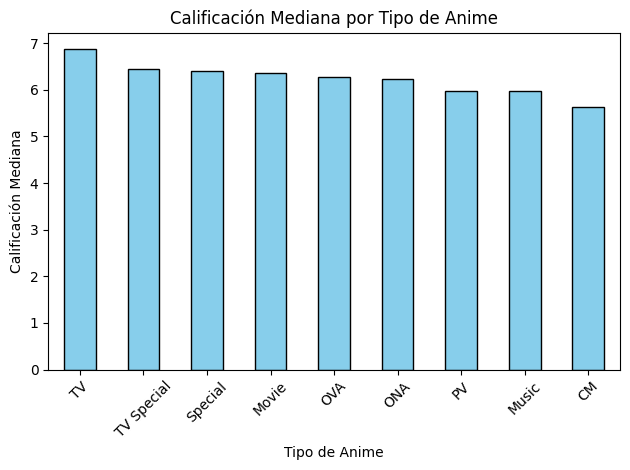

In [ ]:
import matplotlib.pyplot as plt

# Calculamos la mediana de Score por cada Tipo de Anime.
mediana_por_tipo = anime.groupby("Type")["Score"].median().sort_values(ascending=False)

# Graficamos un diagrama de barras.
mediana_por_tipo.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Calificación Mediana por Tipo de Anime")
plt.xlabel("Tipo de Anime")
plt.ylabel("Calificación Mediana")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Interpretación**: Observamos que los animes de TV presenta la puntuación mediana más elevada (6,88). En cambio, los musicales tienen una posición mediana de popularidad de (19517.5) lo que indica una posición menos favorable en el ranking. Estos resultados sugieren que existen diferencias de popularidad según el tipo de anime, aunque no permiten afirmar que el tipo sea la causa de esas diferencias.

**Resumen estadistico según el tipo de fuente original** – Podriamos preguntarnos si la popularidad depende si el anime tiene fuente original o porque son adaptaciones a mangas u otras fuentes que ya tenian más público.

In [ ]:
resumen_source = anime.groupby("Source").agg(
    Cantidad=("Name", "count"),
    Mediana_Score=("Score", "median"),
    Mediana_Popularity=("Popularity", "median")
).sort_values("Mediana_Score", ascending=False)

display(resumen_source)

,Cantidad,Mediana_Score,Mediana_Popularity
Source,,,
Web novel,336,7.280,12635.5
Light novel,1185,6.930,2660.0
Manga,5293,6.850,6450.0
Web manga,584,6.730,5903.0
Novel,560,6.625,9966.5
4-koma manga,321,6.620,6357.0
Card game,76,6.510,9552.0
Mixed media,209,6.470,9623.0
Book,130,6.390,12823.0


**Veamoslo de forma gráfica**

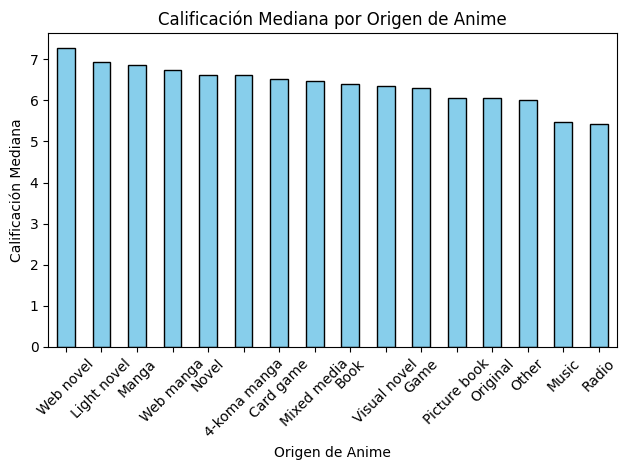

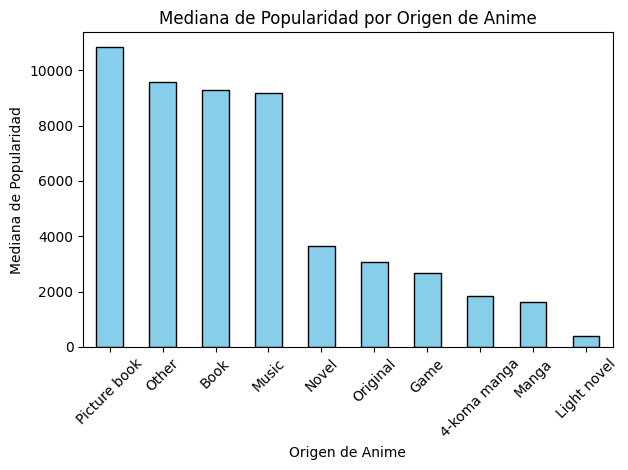

In [ ]:
import matplotlib.pyplot as plt

# Calculamos la mediana de Score por cada Tipo de Anime.
mediana_por_origen = anime.groupby("Source")["Score"].median().sort_values(ascending=False)

# Graficamos un diagrama de barras.
mediana_por_tipo.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Calificación Mediana por Origen de Anime")
plt.xlabel("Origen de Anime")
plt.ylabel("Calificación Mediana")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

mediana_de_popularidad_por_origen = anime.groupby("Source")["Popularity"].median().sort_values(ascending=False)

mediana_de_popularidad_por_origen.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Mediana de Popularidad por Origen de Anime")
plt.xlabel("Origen de Anime")
plt.ylabel("Mediana de Popularidad")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Interpretación:** Dado este análisis se observa que los anime adaptados de "Web novel" tienen mucha más puntuación y público que otras fuentes. Si lo comparamos con animes con fuente original la diferencia es demasiada ya que esta fuente roza los últimos lugares con menos popularidad y menos puntuación. Por lo que podriamos decir que las adaptaciones de novelas web tienen la posibilidad de ser más populares que las originales.

**Resumen estadistico según el género del anime** – Decidimos agrupar los animes según su género porque queríamos investigar si existen diferencias de popularidad entre ellos. Consideramos que las preferencias de los espectadores por determinados géneros podrían estar relacionadas con la cantidad de personas que siguen un anime, su puntuación y su posición en el ranking de popularidad. De esta manera, podemos comparar los géneros e identificar posibles tendencias en los datos.

Asistencia de IA: *“Cómo agrupo por género si la columna tiene varios géneros separados por coma.*”. Se usó este prompt porque se encontró que varios animes tienen varios géneros. Asi que decidimos armar una fila con cada genero e incluir los animes para mayor organización.

In [ ]:

# Separamos los géneros y creamos una fila por cada género de cada anime
generos = anime.assign(
    Genres=anime["Genres"].str.split(", ")
).explode("Genres")

# Calculamos los estadísticos agrupados por género
resumen_generos = generos.groupby("Genres").agg(
    Cantidad=("Name", "count"),
    Mediana_Score=("Score", "median"),
    Mediana_Popularity=("Popularity", "median")
).sort_values("Mediana_Score", ascending=False)

display(resumen_generos)


,Cantidad,Mediana_Score,Mediana_Popularity
Genres,,,
Award Winning,233,7.540,2899.0
Iyashikei,174,7.520,4186.5
Love Status Quo,44,7.370,1885.0
Childcare,69,7.310,4059.0
Urban Fantasy,207,7.270,1833.0
...,...,...,...
Parody,702,6.175,10287.5
Music,3650,6.010,18295.5
Erotica,79,5.980,5538.0


**Veamoslo de forma gráfica**

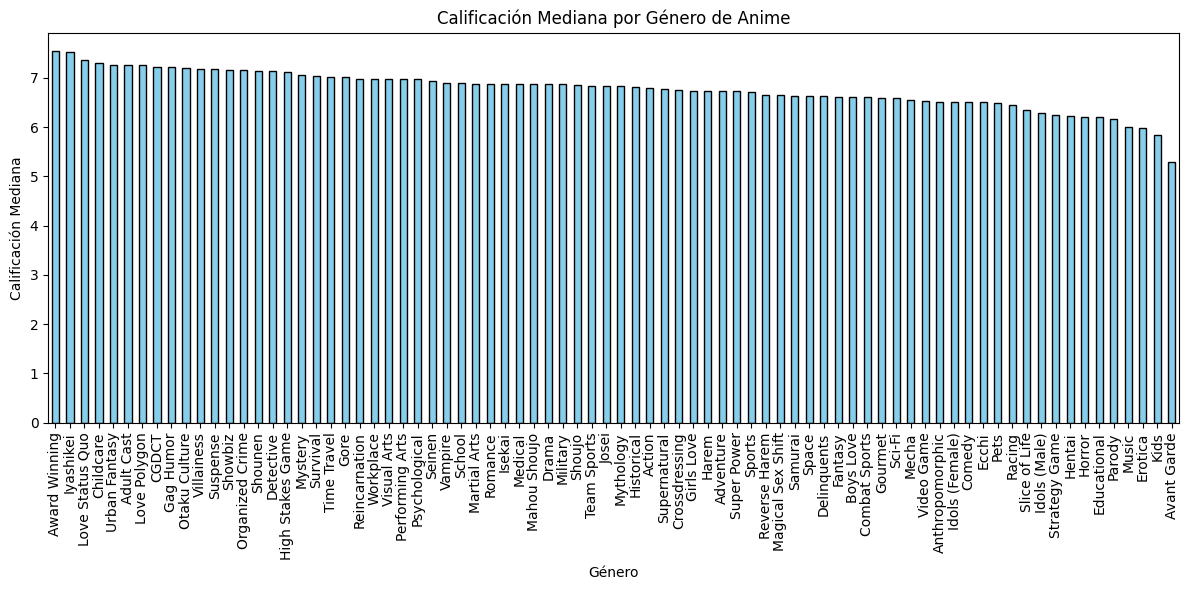

In [ ]:
import matplotlib.pyplot as plt

# Calculamos la mediana de Score por géneros.
mediana_por_genero = generos.groupby("Genres")["Score"].median().sort_values(ascending=False)

# Graficamos un diagrama de barras.
plt.figure(figsize=(12, 6))
mediana_por_genero.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Calificación Mediana por Género de Anime")
plt.xlabel("Género")
plt.ylabel("Calificación Mediana")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Interpretación:** De esta tabla podemos concluir que "Award Winning" tiene la mediana de calificación más alta, con (7,54) puntos. En cambio, "Avant Garde" presenta la mediana más baja, con (5,29) puntos.

En cuanto al ranking de popularidad, "Urban Fantasy" tiene la mejor posición entre los géneros mostrados, con una mediana de (1833), mientras que "Avant Garde" tiene una posición menos favorable, con (17.608,5).

Esto muestra que las calificaciones y la popularidad varían según el género.